# Predicting Fuel Efficiency Across Model Years

**Question:** How well do models trained on 1970s vehicles predict city-cycle miles per gallon for vehicles from 1980–1982?

Compare a median baseline, ridge regression, and random forest. Select by mean validation MAE using forward-in-time validation within the 1970s. Evaluate the selected model once on the 1980–1982 holdout.

This setup is deliberately harder than a random split: it asks whether the model transfers to later vehicle model years. It is a historical learning exercise, not an estimate for modern cars.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    raise RuntimeError("Run this notebook from the project folder containing data/.")
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 15, "font.size": 10})
COLORS = ["#167D9A", "#E59236", "#7557A5"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()

def save_json(name, obj):
    (OUT / name).write_text(json.dumps(obj, indent=2, allow_nan=False) + "\n", encoding="utf-8")

def verify_source(filename):
    manifest = json.loads((ROOT / "data" / "provenance.json").read_text())
    actual = hashlib.sha256((ROOT / "data" / filename).read_bytes()).hexdigest()
    assert actual == manifest["sha256"], "The raw data changed; review provenance before rerunning."
    return manifest

save_json("environment.json", {"python": platform.python_version(), **{
    p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "scikit-learn", "nbclient", "nbformat"]}})


## 1. Load and audit the historical records

[UCI Auto MPG](https://archive.ics.uci.edu/dataset/9/auto%2Bmpg), Quinlan (1993), [DOI](https://doi.org/10.24432/C5859H), CC BY 4.0. There are 398 rows; horsepower uses `?` for missing values. Parse it as missing instead of dropping the entire record. The car name is an identifier and is excluded from model features. Origin is a category, not a magnitude.

The target is city-cycle MPG. Other fields include weight (pounds), displacement (cubic inches), horsepower, acceleration (0–60 mph seconds), cylinders, and model year.


In [2]:
import shlex
verify_source("auto-mpg.data")
columns = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin", "car_name"]
records = [shlex.split(line) for line in (ROOT / "data/auto-mpg.data").read_text().splitlines() if line.strip()]
df = pd.DataFrame(records, columns=columns)
for column in columns[:-1]:
    df[column] = pd.to_numeric(df[column].replace("?", np.nan), errors="raise")
assert len(df) == 398 and df.horsepower.isna().sum() == 6
assert not df.drop(columns="horsepower").isna().any().any()
assert not df.duplicated().any()
assert set(df.origin.unique()) == {1, 2, 3}
display(df.head())
display(df.isna().sum().rename("missing_rows").to_frame())
print("Year range:", int(df.model_year.min()) + 1900, "to", int(df.model_year.max()) + 1900)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


,missing_rows
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


Year range: 1970 to 1982


## 2. Separate later years, then explore training data

All model years through 1979 form the development set. Model years 1980–1982 form the test set. This boundary is chosen in advance. It is a model-year split, not a record of when a car was sold or measured. Related manufacturers/models can still occur on both sides.

Missing horsepower is filled with the training median inside each fit. Numeric variables are standardized inside the pipeline; origin is one-hot encoded. No cleaning parameter is estimated from held-out outcomes.


,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg
count,309.00,309.00,307.00,309.00,309.00,309.00,309.00
mean,5.78,212.64,111.23,3114.37,15.26,74.57,21.10
std,1.75,108.51,40.09,880.86,2.76,2.84,6.47
min,3.00,68.00,46.00,1613.00,8.00,70.00,9.00
25%,4.00,111.00,83.00,2279.00,13.50,72.00,16.00
50%,6.00,200.00,100.00,3039.00,15.00,75.00,20.00
75%,8.00,305.00,141.00,3830.00,17.00,77.00,26.00
max,8.00,455.00,230.00,5140.00,24.80,79.00,43.10


Development rows: 309; held-out rows: 89


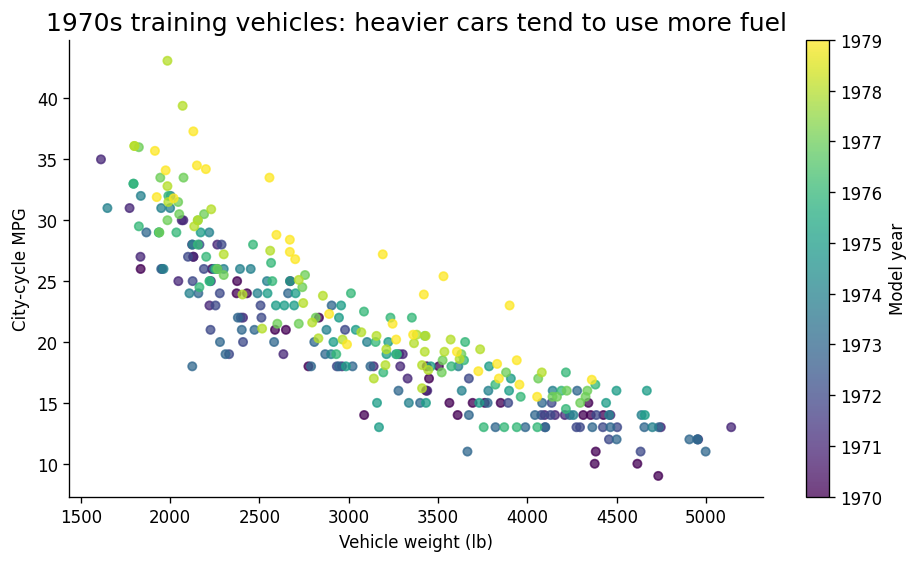

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

numeric = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
features = numeric + ["origin"]
train = df.loc[df.model_year <= 79].copy()
test = df.loc[df.model_year >= 80].copy()
X_train, y_train = train[features], train.mpg
X_test, y_test = test[features], test.mpg
assert train.model_year.max() < test.model_year.min()
assert set(train.index).isdisjoint(test.index)
assert len(train) + len(test) == len(df)
display(train[numeric + ["mpg"]].describe().round(2))
print(f"Development rows: {len(train)}; held-out rows: {len(test)}")
fig, ax = plt.subplots(figsize=(8, 4.8))
points = ax.scatter(train.weight, train.mpg, c=train.model_year + 1900, cmap="viridis", s=25, alpha=0.75)
fig.colorbar(points, ax=ax, label="Model year")
ax.set(xlabel="Vehicle weight (lb)", ylabel="City-cycle MPG", title="1970s training vehicles: heavier cars tend to use more fuel")
savefig("training_weight_vs_mpg.png")

def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("origin", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["origin"]),
    ])

models = {
    "median_baseline": Pipeline([("prep", make_preprocessor()), ("model", DummyRegressor(strategy="median"))]),
    "ridge": Pipeline([("prep", make_preprocessor()), ("model", Ridge(alpha=1.0))]),
    "random_forest": Pipeline([("prep", make_preprocessor()),
        ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=1))]),
}


## 3. Select a model using forward validation

Each validation fold holds out one year from 1975–1979 and trains only on earlier model years. Unlike ordinary shuffled cross-validation, this does not let later vehicles inform earlier validation predictions. The score is the mean of the five year-level MAEs, so each validation year has equal weight. This selection score can still be optimistic because it chooses among candidates.

MAE is the average absolute error in MPG: lower is better. The standard deviation measures variation among those five historical validation years.


,validation_year,fit_rows,validation_rows
0,1975,152,30
1,1976,182,34
2,1977,216,28
3,1978,244,36
4,1979,280,29


,model,cv_mae_mean,cv_mae_sd
2,random_forest,2.172,0.555
1,ridge,2.453,0.508
0,median_baseline,5.595,0.931


Selected by forward-validation MAE: random_forest


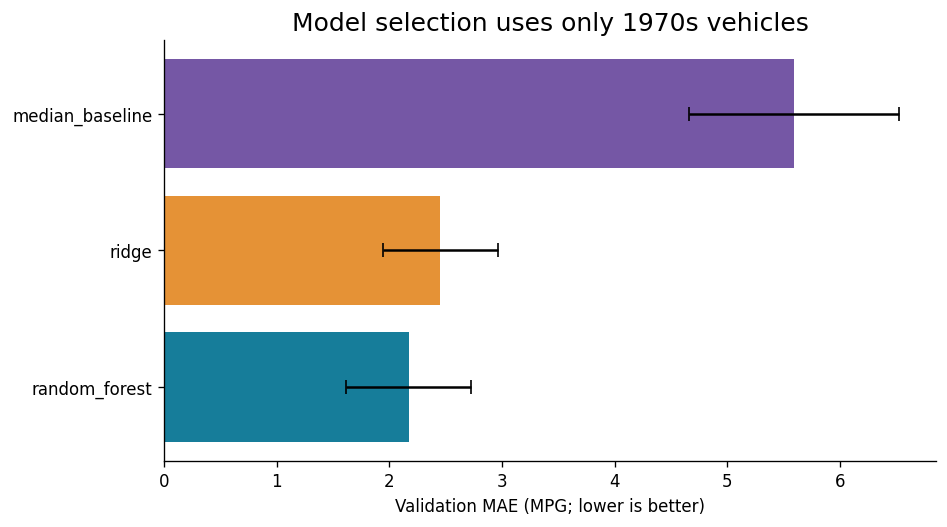

In [4]:
folds, fold_details = [], []
for validation_year in range(75, 80):
    fit_idx = np.flatnonzero(train.model_year.to_numpy() < validation_year)
    val_idx = np.flatnonzero(train.model_year.to_numpy() == validation_year)
    assert len(fit_idx) > 0 and len(val_idx) > 0
    assert train.iloc[fit_idx].model_year.max() < train.iloc[val_idx].model_year.min()
    assert set(train.index[val_idx]).isdisjoint(test.index)
    folds.append((fit_idx, val_idx))
    fold_details.append({"validation_year": validation_year + 1900, "fit_rows": len(fit_idx), "validation_rows": len(val_idx)})
display(pd.DataFrame(fold_details))
cv_rows = []
fold_scores = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=folds, scoring="neg_mean_absolute_error", error_score="raise")
    errors = -scores["test_score"]
    cv_rows.append({"model": name, "cv_mae_mean": errors.mean(), "cv_mae_sd": errors.std(ddof=1)})
    fold_scores.extend({"model": name, "validation_year": year + 1900, "mae": float(error)}
                       for year, error in zip(range(75, 80), errors))
cv_results = pd.DataFrame(cv_rows).sort_values(["cv_mae_mean", "model"])
selected_name = cv_results.iloc[0].model
display(cv_results.round(3))
print("Selected by forward-validation MAE:", selected_name)
cv_results.to_csv(OUT / "cross_validation.csv", index=False)
pd.DataFrame(fold_scores).to_csv(OUT / "validation_by_year.csv", index=False)
save_json("split.json", {"train_row_ids": train.index.tolist(), "test_row_ids": test.index.tolist(),
                         "strategy": "train 1970-1979, test 1980-1982", "validation_folds": fold_details})
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cv_results.model, cv_results.cv_mae_mean, xerr=cv_results.cv_mae_sd, color=COLORS, capsize=4)
ax.set(xlabel="Validation MAE (MPG; lower is better)", title="Model selection uses only 1970s vehicles")
savefig("model_comparison.png")


## 4. Evaluate once on 1980–1982 vehicles

MAE describes average absolute error; RMSE weights large errors more heavily; R² compares squared error with predicting the test-set mean and can be negative. The practical baseline here uses the training median, which is distinct from that R² reference.

Inspect error by model year and signed residuals (actual minus predicted). Positive residuals mean underprediction. These test diagnostics explain the result; they are not used to refit or choose a different model.


,n,mae,mean_residual
model_year,,,
80,29,5.481,4.582
81,29,2.898,1.916
82,31,3.434,2.898


Five largest absolute errors:


,car_name,model_year,actual_mpg,predicted_mpg,baseline_mpg,residual_mpg,absolute_error_mpg
387,oldsmobile cutlass ciera (diesel),82,38.0,20.71,20.0,17.29,17.29
333,datsun 280-zx,80,32.7,19.34,20.0,13.36,13.36
326,vw dasher (diesel),80,43.4,30.41,20.0,12.99,12.99
322,mazda glc,80,46.6,33.88,20.0,12.72,12.72
327,audi 5000s (diesel),80,36.4,23.84,20.0,12.56,12.56


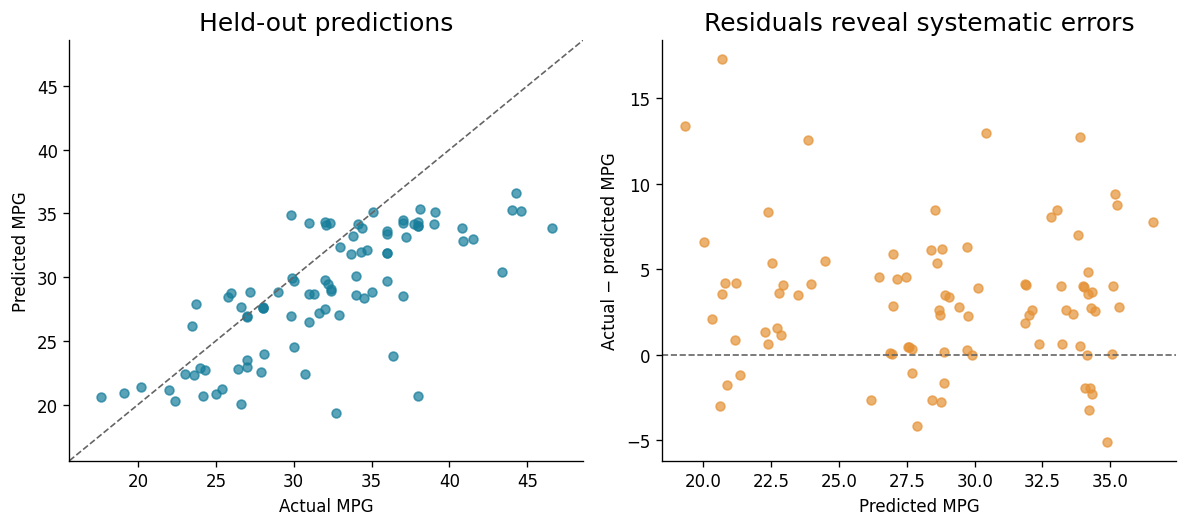

**Result:** random_forest has a held-out MAE of **3.93 MPG**, compared with **11.98 MPG** for the training-median baseline (67.2% lower MAE). RMSE is 5.14 MPG and R² is 0.287.

In [5]:
selected = clone(models[selected_name]).fit(X_train, y_train)
prediction = selected.predict(X_test)
baseline = clone(models["median_baseline"]).fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)
predictions = test[["car_name", "model_year", "mpg"]].rename(columns={"mpg": "actual_mpg"}).copy()
predictions["predicted_mpg"] = prediction
predictions["baseline_mpg"] = baseline_prediction
predictions["residual_mpg"] = y_test.to_numpy() - prediction
predictions["absolute_error_mpg"] = np.abs(predictions.residual_mpg)
predictions.to_csv(OUT / "test_predictions.csv", index_label="raw_row_id")
by_year = predictions.groupby("model_year").agg(n=("actual_mpg", "size"), mae=("absolute_error_mpg", "mean"), mean_residual=("residual_mpg", "mean"))
display(by_year.round(3))
by_year.to_csv(OUT / "test_error_by_year.csv")
print("Five largest absolute errors:")
display(predictions.nlargest(5, "absolute_error_mpg").round(2))
mae = mean_absolute_error(y_test, prediction)
baseline_mae = mean_absolute_error(y_test, baseline_prediction)
results = {"raw_rows": len(df), "missing_horsepower": int(df.horsepower.isna().sum()),
           "train_rows": len(train), "test_rows": len(test), "selected_model": selected_name,
           "test_mae_mpg": float(mae), "test_rmse_mpg": float(root_mean_squared_error(y_test, prediction)),
           "test_r2": float(r2_score(y_test, prediction)), "baseline_test_mae_mpg": float(baseline_mae),
           "mae_reduction_percent": float(100*(baseline_mae-mae)/baseline_mae),
           "mean_residual_mpg": float(predictions.residual_mpg.mean()),
           "cross_validation": cv_results.to_dict(orient="records")}
assert np.isfinite(prediction).all() and len(prediction) == len(test)
save_json("metrics.json", results)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(y_test, prediction, color=COLORS[0], alpha=0.7, s=28)
limits = [min(y_test.min(), prediction.min())-2, max(y_test.max(), prediction.max())+2]
axes[0].plot(limits, limits, linestyle="--", color="#656565", linewidth=1)
axes[0].set(xlabel="Actual MPG", ylabel="Predicted MPG", title="Held-out predictions", xlim=limits, ylim=limits)
axes[1].scatter(prediction, y_test.to_numpy()-prediction, color=COLORS[1], alpha=0.7, s=28)
axes[1].axhline(0, linestyle="--", color="#656565", linewidth=1)
axes[1].set(xlabel="Predicted MPG", ylabel="Actual − predicted MPG", title="Residuals reveal systematic errors")
savefig("prediction_diagnostics.png")
display(Markdown(f"**Result:** {selected_name} has a held-out MAE of **{mae:.2f} MPG**, "
                 f"compared with **{baseline_mae:.2f} MPG** for the training-median baseline "
                 f"({results['mae_reduction_percent']:.1f}% lower MAE). "
                 f"RMSE is {results['test_rmse_mpg']:.2f} MPG and R² is {results['test_r2']:.3f}."))


## Conclusions and limits

The reported comparison shows how well the chosen model transfers to later model years. Performance may deteriorate when fuel efficiency, vehicle mix, or engineering changes over time. A random forest averages training outcomes and cannot freely extrapolate beyond them; ridge can extrapolate but imposes an approximately linear relationship.

This is a small historical sample, not a modern vehicle benchmark. Related car models may cross the time boundary; manufacturer-level generalization is not established. A model-year split approximates a forecasting problem but does not provide actual acquisition timestamps. Correlations are not causal effects of changing vehicle weight or horsepower.

**Next experiment:** add group-aware validation by manufacturer, or reserve a new temporal holdout before trying nonlinear features. Do not tune repeatedly against the 1980–1982 results.

**Learning checks:** Why is a time split harder than a random split? Why impute separately inside each fold? Why can R² be low even when a model improves substantially on the training-median baseline?
